In [1]:
# NB-05: Búsqueda Adversarial (Juegos)
# Generado para: Andrés Hormazábal — UDP
# Parte del sistema de 25 notebooks de estudio ML/IA
# Fecha de generación: 2026-10-30

# NB-05: Búsqueda Adversarial (Juegos)

**Bloque:** 2 — IA Clásica (curso CIT-2013, AIMA)

**Base bibliográfica:** AIMA 4.ª ed., cap. 5 (*Adversarial Search and Games*) ·
cap. 5.4 (corte heurístico y funciones de evaluación) · cap. 5.5 (*Monte Carlo Tree
Search*) · cap. 5.6 (juegos estocásticos) · Knuth & Moore (1975) para el análisis de
alfa-beta

**Prerequisitos:** NB-04 (el marco `Problem`, DFS, el concepto de heurística y la
diferencia entre búsqueda en árbol y en grafo). De NB-03 solo se usa `rng` y algo de
NumPy para los conteos.

## Objetivos de Aprendizaje

Al completar este notebook serás capaz de:

1. **Formular** un juego como un problema de búsqueda adversarial (los 6 componentes) y
   explicar en qué se diferencia de la formulación de NB-04.
2. **Implementar** minimax y demostrar por qué produce juego óptimo contra un rival
   óptimo.
3. **Implementar** poda alfa-beta y **demostrar empíricamente** que no cambia el
   resultado, solo el número de nodos.
4. **Explicar y medir** por qué el orden de los movimientos cambia la poda de
   $O(b^m)$ a $O(b^{m/2})$ en el mejor caso.
5. **Diseñar** una función de evaluación y entender el *horizon effect* que introduce.
6. **Aplicar** expectiminimax a juegos con azar, y MCTS/UCT cuando no hay función de
   evaluación decente.
7. **Elegir con criterio** entre alfa-beta y MCTS según las características del juego.

| Curso / Área | Relevancia |
|---|---|
| IA (CIT-2013) | **Materia directa de la Solemne 2** (AIMA cap. 5). Minimax y alfa-beta se preguntan a mano sobre árboles dibujados. |
| Big Data (CIT-2309) | MCTS es un algoritmo de *anytime*: devuelve una respuesta cada vez mejor con más cómputo. El mismo compromiso que viste en LSH (NB-03) y en SA (NB-04). |
| Comunicaciones / Tesis | Teoría de juegos aplicada a asignación de recursos y control de potencia; equilibrio de Nash como análogo del valor minimax. |
| Notebooks relacionados | NB-04 (base: el marco `Problem`, búsqueda local), NB-06 (CSP), NB-08 (probabilidad: expectiminimax usa esperanza), NB-19 (aprendizaje por refuerzo: MCTS es su antepasado) |

## Tabla de contenidos

1. Marco teórico: qué cambia cuando hay un adversario
2. Configuración
3. Un marco de juegos reutilizable
4. Minimax: el algoritmo y su garantía
5. Poda alfa-beta
6. Corte por profundidad y funciones de evaluación
7. Juegos con azar: expectiminimax
8. Monte Carlo Tree Search (MCTS/UCT)
9. Tabla comparativa y árbol de decisión
10. 📋 Cheat Sheet
11. Conexiones con el mundo real
12. Ejercicios progresivos
13. Resumen y siguiente paso

## 1. Marco teórico: qué cambia cuando hay un adversario

### La intuición: el plan deja de ser tuyo

En NB-04, cuando encontrabas una ruta `Arad → Sibiu → Rimnicu → Pitesti → Bucarest`,
esa ruta **era tuya**: nadie podía impedirte ejecutarla. Toda la secuencia estaba bajo
tu control.

En un juego eso se acaba. Tú eliges una jugada, pero la siguiente la elige **alguien
que quiere que pierdas**. Ya no buscas una *secuencia*, buscas una **estrategia**: un
plan que diga qué hacer en cada respuesta posible del rival.

```
BÚSQUEDA DE NB-04                      BÚSQUEDA ADVERSARIAL
(todos los nodos son tuyos)            (los niveles se alternan)

        o  tú                                  △  MAX (tú)
       /|\                                    /|\
      o o o  tú                              ▽ ▽ ▽  MIN (rival)
     /|\                                    /|\
    o o o  tú                              △ △ △  MAX (tú)

Buscas: UN camino hasta la meta          Buscas: una RESPUESTA a cada
Resultado: una secuencia                 jugada posible del rival
                                         Resultado: una política
```

### Los seis componentes de un juego (AIMA 5.1)

| Componente | Qué es | En el tres en raya |
|---|---|---|
| $S_0$ | estado inicial | tablero vacío |
| `to_move(s)` | a quién le toca | `X` o `O` |
| `actions(s)` | jugadas legales | casillas libres |
| `result(s, a)` | estado resultante | tablero con la marca puesta |
| `is_terminal(s)` | ¿se acabó? | hay línea o no quedan casillas |
| `utility(s, p)` | valor final **para el jugador p** | +1 gana, 0 empata, −1 pierde |

Los cuatro primeros son casi idénticos a los de `Problem` en NB-04. **Los dos que
cambian todo son `to_move` y `utility`**: uno introduce la alternancia, el otro
reemplaza "costo que quiero minimizar" por "utilidad que quiero maximizar y mi rival
minimizar".

### El supuesto que hay que tener presente

Minimax supone que **el rival juega óptimo**. Eso lo hace pesimista: si tu rival se
equivoca, te irá mejor que lo previsto, nunca peor. Es una garantía de **peor caso**,
exactamente como la admisibilidad de una heurística garantizaba el peor caso en A*.

> **Idea clave.** El valor minimax de un estado es el resultado que puedes **garantizar**
> jugando bien, sin importar qué haga el otro. No es el resultado más probable: es el
> que no te pueden quitar.

### Los dos muros, y los dos escapes

El tres en raya tiene $\approx 5.5 \times 10^5$ nodos: minimax completo cabe. El ajedrez
tiene $b\approx35$, $m\approx80$, o sea $35^{80}$ estados. Go, mucho más. Hay dos muros:

1. **El árbol es demasiado grande para llegar a las hojas.**
   → Escape: **cortar antes** y estimar con una función de evaluación (§6).
2. **No siempre existe una buena función de evaluación** (el caso de Go durante
   décadas).
   → Escape: **simular partidas al azar** y promediar: MCTS (§8).

Y transversal a los dos: **podar** ramas que no pueden influir en el resultado
(alfa-beta, §5), que no aproxima nada — da el mismo resultado exacto visitando menos.

## 2. Configuración

In [2]:
# === Imports ===
import math
import random
import time
from abc import ABC, abstractmethod
from dataclasses import dataclass, field
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# --- Reproducibilidad ---
SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)          # se pasa explícitamente (como en NB-03/04)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "figure.figsize": (9, 4.5),
                     "axes.titlesize": 12, "grid.alpha": 0.35})
pd.set_option("display.max_columns", 30)

print(f"NumPy {np.__version__} | pandas {pd.__version__}")

NumPy 2.5.4 | pandas 3.1.0


## 3. Un marco de juegos reutilizable

Mismo patrón que `Problem` en NB-04: **el algoritmo no sabe nada del juego**. Eso
permite escribir minimax una sola vez y correrlo sobre tres juegos distintos sin tocar
una línea.

In [3]:
class Game(ABC):
    """Los 6 componentes de AIMA 5.1. Cada juego concreto hereda de aquí."""

    @abstractmethod
    def actions(self, estado) -> list: ...

    @abstractmethod
    def result(self, estado, accion): ...

    @abstractmethod
    def is_terminal(self, estado) -> bool: ...

    @abstractmethod
    def utility(self, estado, jugador) -> float:
        """Valor del estado TERMINAL desde el punto de vista de `jugador`."""

    @abstractmethod
    def to_move(self, estado): ...

    def display(self, estado) -> str:
        return str(estado)


@dataclass
class Contador:
    """Instrumentación: sin medir nodos, 'alfa-beta es más rápido' es una creencia."""
    nodos: int = 0
    podas: int = 0
    def reset(self): self.nodos = self.podas = 0


CNT = Contador()

In [4]:
class TicTacToe(Game):
    """Tres en raya 3×3. Estado = (tablero, jugador_en_turno).

    El tablero es una TUPLA de 9 elementos ('X', 'O' o None). Usar una tupla
    (inmutable y hasheable) en vez de una lista no es capricho: permite meter
    estados en diccionarios y en lru_cache, que es la base de la tabla de
    transposición de §6.3.
    """
    LINEAS = [(0,1,2), (3,4,5), (6,7,8),      # filas
              (0,3,6), (1,4,7), (2,5,8),      # columnas
              (0,4,8), (2,4,6)]               # diagonales

    def __init__(self, n=3):
        self.inicial = ((None,) * 9, "X")

    def to_move(self, estado): return estado[1]

    def actions(self, estado):
        tablero, _ = estado
        return [i for i, v in enumerate(tablero) if v is None]

    def result(self, estado, accion):
        tablero, jugador = estado
        nuevo = list(tablero); nuevo[accion] = jugador
        return (tuple(nuevo), "O" if jugador == "X" else "X")

    def ganador(self, tablero):
        for a, b, c in self.LINEAS:
            if tablero[a] is not None and tablero[a] == tablero[b] == tablero[c]:
                return tablero[a]
        return None

    def is_terminal(self, estado):
        tablero, _ = estado
        return self.ganador(tablero) is not None or all(v is not None for v in tablero)

    def utility(self, estado, jugador):
        g = self.ganador(estado[0])
        if g is None: return 0.0                       # empate
        return 1.0 if g == jugador else -1.0

    def display(self, estado):
        t = estado[0]
        f = lambda i: t[i] if t[i] else str(i)
        return "\n---------\n".join(" " + " | ".join(f(r * 3 + c) for c in range(3))
                                    for r in range(3))


ttt = TicTacToe()
s = ttt.inicial
for a in (4, 0, 8):
    s = ttt.result(s, a)
print(ttt.display(s))
print(f"\nturno de: {ttt.to_move(s)} | jugadas legales: {ttt.actions(s)}")
print(f"¿terminal? {ttt.is_terminal(s)}")

 O | 1 | 2
---------
 3 | X | 5
---------
 6 | 7 | X

turno de: O | jugadas legales: [1, 2, 3, 5, 6, 7]
¿terminal? False


## 4. Minimax: el algoritmo y su garantía

### 4.1 La recursión, en una frase

> El valor de un estado donde juega **MAX** es el **máximo** de los valores de sus
> hijos; donde juega **MIN**, el **mínimo**. En las hojas, es la utilidad.

$$
\text{minimax}(s)=
\begin{cases}
\text{utility}(s) & \text{si } s \text{ es terminal}\\
\max_{a \in \text{actions}(s)} \text{minimax}(\text{result}(s,a)) & \text{si juega MAX}\\
\min_{a \in \text{actions}(s)} \text{minimax}(\text{result}(s,a)) & \text{si juega MIN}
\end{cases}
$$

Es un **DFS postorden**: para saber el valor de un nodo necesitas primero el de todos
sus hijos. Por eso la memoria es $O(bm)$ (solo el camino actual más los hermanos
pendientes) aunque el tiempo sea $O(b^m)$.

```
                 MAX                         ¿qué elige MAX? el 3
                 (3)
        ┌─────────┼─────────┐
      MIN(3)    MIN(2)    MIN(2)             cada MIN toma el MENOR de sus hijos
     ┌──┼──┐   ┌──┼──┐   ┌──┼──┐
     3  12  8  2  4  6   14  5  2
```

> ⚠ **TRAMPA que se pregunta siempre.** `utility(s, jugador)` debe evaluarse **siempre
> desde el punto de vista del mismo jugador** (el de la raíz), no del que está en turno.
> Si el signo cambia a mitad del árbol, el algoritmo devuelve basura sin fallar. Es el
> error número uno al implementar minimax.

In [5]:
def minimax_valor(juego, estado, jugador, cnt=CNT):
    """Valor minimax de `estado` desde el punto de vista FIJO de `jugador`."""
    cnt.nodos += 1
    if juego.is_terminal(estado):
        return juego.utility(estado, jugador)
    if juego.to_move(estado) == jugador:                       # nodo MAX
        return max(minimax_valor(juego, juego.result(estado, a), jugador, cnt)
                   for a in juego.actions(estado))
    return min(minimax_valor(juego, juego.result(estado, a), jugador, cnt)   # nodo MIN
               for a in juego.actions(estado))


def minimax_decision(juego, estado, cnt=CNT):
    """La jugada que maximiza el valor minimax. Devuelve (jugada, valor)."""
    jugador = juego.to_move(estado)
    mejor_a, mejor_v = None, -math.inf
    for a in juego.actions(estado):
        v = minimax_valor(juego, juego.result(estado, a), jugador, cnt)
        if v > mejor_v:
            mejor_a, mejor_v = a, v
    return mejor_a, mejor_v


CNT.reset(); t0 = time.perf_counter()
jugada, valor = minimax_decision(ttt, ttt.inicial)
t_mm = time.perf_counter() - t0
N_MINIMAX = CNT.nodos
print(f"Desde el tablero vacío: jugada elegida = {jugada}, valor minimax = {valor:+.0f}")
print(f"Nodos visitados: {N_MINIMAX:,}  |  tiempo: {t_mm:.2f} s")

# ¿Cuánto vale CADA apertura? El resultado sorprende y es importante.
valores_apertura = {}
for a in ttt.actions(ttt.inicial):
    valores_apertura[a] = minimax_valor(ttt, ttt.result(ttt.inicial, a), "X", Contador())
print("\nValor minimax de cada apertura:", valores_apertura)
print(f"""
  LEE ESTO CON ATENCIÓN, porque contradice la intuición de todo el mundo:
  las NUEVE aperturas valen 0. Con juego perfecto de ambos lados, el tres en
  raya es empate se juegue lo que se juegue de salida.

  Consecuencias:
  · minimax es INDIFERENTE entre las nueve. Devolvió la {jugada} solo porque es
    la primera que examinó; cualquier criterio de desempate sería igual de
    válido. Si tu compañero obtiene otra jugada, los dos están correctos.
  · "El centro es la mejor apertura" es verdad contra un rival IMPERFECTO, no
    contra uno perfecto. Son dos criterios distintos: maximizar el resultado
    garantizado (minimax) vs. maximizar la probabilidad de ganar contra alguien
    que se puede equivocar. En §8 veremos que MCTS, que simula rivales al azar,
    prefiere claramente el centro — y ahora sabes por qué.
  · Si tu implementación devuelve +1 desde el tablero vacío, tienes un error
    de signo.""")

Desde el tablero vacío: jugada elegida = 0, valor minimax = +0
Nodos visitados: 549,945  |  tiempo: 1.21 s

Valor minimax de cada apertura: {0: 0.0, 1: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0, 8: 0.0}

  LEE ESTO CON ATENCIÓN, porque contradice la intuición de todo el mundo:
  las NUEVE aperturas valen 0. Con juego perfecto de ambos lados, el tres en
  raya es empate se juegue lo que se juegue de salida.

  Consecuencias:
  · minimax es INDIFERENTE entre las nueve. Devolvió la 0 solo porque es
    la primera que examinó; cualquier criterio de desempate sería igual de
    válido. Si tu compañero obtiene otra jugada, los dos están correctos.
  · "El centro es la mejor apertura" es verdad contra un rival IMPERFECTO, no
    contra uno perfecto. Son dos criterios distintos: maximizar el resultado
    garantizado (minimax) vs. maximizar la probabilidad de ganar contra alguien
    que se puede equivocar. En §8 veremos que MCTS, que simula rivales al azar,
    prefiere claramente e

In [6]:
# La demostración de que juega bien: minimax NUNCA pierde, ni contra un rival que
# juega al azar ni contra sí mismo.
def jugar(juego, estrategias, estado=None, mostrar=False):
    """estrategias: dict jugador -> función(juego, estado) -> jugada."""
    estado = estado if estado is not None else juego.inicial
    while not juego.is_terminal(estado):
        jugador = juego.to_move(estado)
        estado = juego.result(estado, estrategias[jugador](juego, estado))
        if mostrar: print(juego.display(estado), "\n")
    return estado


al_azar = lambda j, s: random.choice(j.actions(s))
minimax_jug = lambda j, s: minimax_decision(j, s)[0]

random.seed(SEED)
resultados = []
for i in range(30):
    # minimax juega de X en la mitad y de O en la otra mitad
    estr = ({"X": minimax_jug, "O": al_azar} if i % 2 == 0
            else {"X": al_azar, "O": minimax_jug})
    yo = "X" if i % 2 == 0 else "O"
    fin = jugar(ttt, estr)
    resultados.append(ttt.utility(fin, yo))

r = pd.Series(resultados).value_counts().reindex([1.0, 0.0, -1.0], fill_value=0)
print(f"minimax vs. azar, 30 partidas:  gana {int(r[1.0])}  empata {int(r[0.0])}  "
      f"pierde {int(r[-1.0])}")
print("""
  Cero derrotas. Eso NO es casualidad ni suerte: es la garantía del teorema.
  El valor minimax de la raíz es 0 (empate), así que minimax tiene asegurado
  al menos empatar contra CUALQUIER rival. Un rival que se equivoca solo puede
  mejorar el resultado para minimax, nunca empeorarlo.""")

minimax vs. azar, 30 partidas:  gana 27  empata 3  pierde 0

  Cero derrotas. Eso NO es casualidad ni suerte: es la garantía del teorema.
  El valor minimax de la raíz es 0 (empate), así que minimax tiene asegurado
  al menos empatar contra CUALQUIER rival. Un rival que se equivoca solo puede
  mejorar el resultado para minimax, nunca empeorarlo.


## 5. Poda alfa-beta

### 5.1 La idea, con el ejemplo que basta para entenderla

Minimax visita todo el árbol. Pero hay ramas cuyo valor **no puede cambiar la decisión
de la raíz**, y gastarlas es tiempo perdido.

```
                MAX                  α = mejor valor que MAX tiene ASEGURADO hasta ahora
                 ●                   β = mejor valor que MIN tiene ASEGURADO hasta ahora
        ┌────────┼────────┐
     MIN(=3)   MIN(≤2)   ...
     ┌──┼──┐   ┌──┼──┐
     3  12  8  2  ✂  ✂
                 ↑
   MAX ya tiene asegurado 3 por la rama izquierda (α = 3).
   En la rama central, MIN encuentra un 2. MIN nunca elegirá algo MAYOR que 2,
   así que esta rama vale COMO MUCHO 2. Como 2 < 3, MAX jamás la elegirá.
   → los hermanos restantes son irrelevantes: PODA.
```

**La condición de poda, en una línea:** se poda cuando $\alpha \ge \beta$, es decir,
cuando lo que MAX ya tiene asegurado en otra parte es al menos tan bueno como el techo
que MIN puede ofrecer aquí.

> **Lo más importante, y lo que más se confunde:** alfa-beta **devuelve exactamente el
> mismo valor que minimax**. No es una aproximación ni una heurística. Lo único que
> cambia es cuántos nodos visitas. Si tu alfa-beta da un resultado distinto al de
> minimax, está mal implementado — y abajo lo verificamos con 200 estados al azar.

In [7]:
def alfabeta_valor(juego, estado, jugador, alfa=-math.inf, beta=math.inf, cnt=CNT):
    cnt.nodos += 1
    if juego.is_terminal(estado):
        return juego.utility(estado, jugador)
    if juego.to_move(estado) == jugador:                       # nodo MAX
        v = -math.inf
        for a in juego.actions(estado):
            v = max(v, alfabeta_valor(juego, juego.result(estado, a), jugador,
                                      alfa, beta, cnt))
            if v >= beta:                                      # poda beta
                cnt.podas += 1
                return v
            alfa = max(alfa, v)
        return v
    v = math.inf                                               # nodo MIN
    for a in juego.actions(estado):
        v = min(v, alfabeta_valor(juego, juego.result(estado, a), jugador,
                                  alfa, beta, cnt))
        if v <= alfa:                                          # poda alfa
            cnt.podas += 1
            return v
        beta = min(beta, v)
    return v


def alfabeta_decision(juego, estado, cnt=CNT, orden=None):
    jugador = juego.to_move(estado)
    acciones = juego.actions(estado)
    if orden is not None:
        acciones = orden(juego, estado, acciones)
    mejor_a, mejor_v, alfa = None, -math.inf, -math.inf
    for a in acciones:
        v = alfabeta_valor(juego, juego.result(estado, a), jugador, alfa, math.inf, cnt)
        if v > mejor_v:
            mejor_a, mejor_v = a, v
        alfa = max(alfa, v)
    return mejor_a, mejor_v


CNT.reset(); t0 = time.perf_counter()
j_ab, v_ab = alfabeta_decision(ttt, ttt.inicial)
t_ab = time.perf_counter() - t0
n_ab, p_ab = CNT.nodos, CNT.podas

print(f"{'':12} {'jugada':>8} {'valor':>7} {'nodos':>10} {'tiempo':>9}")
print(f"{'minimax':12} {jugada:>8} {valor:>+7.0f} {N_MINIMAX:>10,} {t_mm:>8.2f}s")
print(f"{'alfa-beta':12} {j_ab:>8} {v_ab:>+7.0f} {n_ab:>10,} {t_ab:>8.2f}s")
print(f"\nMismo valor: {valor == v_ab}   |   reducción de nodos: "
      f"{1 - n_ab / N_MINIMAX:.1%}   |   aceleración: ×{t_mm / t_ab:.1f}")
print(f"Podas realizadas: {p_ab:,}")

               jugada   valor      nodos    tiempo
minimax             0      +0    549,945     1.21s
alfa-beta           0      +0     18,296     0.12s

Mismo valor: True   |   reducción de nodos: 96.7%   |   aceleración: ×9.7
Podas realizadas: 8,180


In [8]:
# La verificación que de verdad importa: ¿coinciden SIEMPRE, no solo en la raíz?
def estado_al_azar(juego, n_jugadas, rnd):
    s = juego.inicial
    for _ in range(n_jugadas):
        if juego.is_terminal(s): break
        s = juego.result(s, rnd.choice(juego.actions(s)))
    return s

rnd = random.Random(7)
discrepancias, comparados = 0, 0
for _ in range(200):
    s = estado_al_azar(ttt, rnd.randint(1, 5), rnd)
    if ttt.is_terminal(s): continue
    p = ttt.to_move(s)
    v1 = minimax_valor(ttt, s, p, Contador())
    v2 = alfabeta_valor(ttt, s, p, cnt=Contador())
    comparados += 1
    discrepancias += (v1 != v2)

print(f"Estados comparados: {comparados} | discrepancias minimax vs alfa-beta: {discrepancias}")
print("""
  Cero discrepancias. Esta es la prueba que hay que escribir SIEMPRE que se
  implementa una optimización: que el resultado no cambia. Una optimización que
  "va más rápido" pero altera la respuesta no es una optimización, es un bug.""")

Estados comparados: 196 | discrepancias minimax vs alfa-beta: 0

  Cero discrepancias. Esta es la prueba que hay que escribir SIEMPRE que se
  implementa una optimización: que el resultado no cambia. Una optimización que
  "va más rápido" pero altera la respuesta no es una optimización, es un bug.


### 5.2 El orden de las jugadas: de $O(b^m)$ a $O(b^{m/2})$

La poda depende de **encontrar pronto una jugada buena**. Si la mejor jugada se examina
primero, $\alpha$ sube de inmediato y poda todo lo demás. Si se examina última, no poda
nada.

| Orden de las jugadas | Nodos examinados | Equivale a |
|---|---|---|
| El peor posible | $O(b^m)$ | minimax sin podar |
| Aleatorio | $O(b^{3m/4})$ | |
| **El mejor posible** | $O(b^{m/2})$ | **el doble de profundidad con el mismo cómputo** |

Ese $b^{m/2}$ es el resultado de Knuth & Moore (1975) y es espectacular: con el mismo
presupuesto de cómputo puedes mirar **el doble de jugadas hacia adelante**. En ajedrez,
es la diferencia entre jugar como aficionado y como maestro.

Claro, hay una circularidad evidente: *para ordenar bien necesitarías saber cuál es la
mejor jugada, que es justo lo que estás calculando*. En la práctica se usan
aproximaciones baratas: jugadas que capturan primero, la mejor jugada de la iteración
anterior (*iterative deepening*), o una tabla de transposición.

In [9]:
# ¿Por qué el tres en raya NO sirve para medir el efecto del orden?
# Porque todas las aperturas valen 0: alfa nunca sube en la raíz, así que no
# hay "jugada buena encontrada pronto" que aprovechar. Lo medimos sobre un
# árbol sintético con valores variados, que es donde la ley se puede observar.

def arbol_aleatorio(b, m, rnd):
    """Árbol de ramificación b y profundidad m, con valores al azar en las hojas."""
    if m == 0:
        return rnd.randint(0, 99)
    return [arbol_aleatorio(b, m - 1, rnd) for _ in range(b)]


def minimax_arbol(nodo, es_max=True):
    if not isinstance(nodo, list): return nodo
    f = max if es_max else min
    return f(minimax_arbol(h, not es_max) for h in nodo)


def ab_arbol(nodo, alfa=-math.inf, beta=math.inf, es_max=True, orden="ninguno",
             cnt=None):
    """Alfa-beta sobre el árbol, con tres políticas de orden de los hijos."""
    if not isinstance(nodo, list):
        cnt[0] += 1                      # contamos HOJAS evaluadas
        return nodo
    hijos = nodo
    if orden != "ninguno":
        # orden ORÁCULO: ordena por el valor verdadero del hijo. En la práctica
        # no se puede (es lo que estás calculando); aquí sirve para medir la COTA.
        claves = [minimax_arbol(h, not es_max) for h in hijos]
        pares = sorted(zip(claves, range(len(hijos))),
                       reverse=(orden == "mejor" if es_max else orden != "mejor"))
        hijos = [nodo[i] for _, i in pares]
    if es_max:
        v = -math.inf
        for h in hijos:
            v = max(v, ab_arbol(h, alfa, beta, False, orden, cnt))
            if v >= beta: return v
            alfa = max(alfa, v)
        return v
    v = math.inf
    for h in hijos:
        v = min(v, ab_arbol(h, alfa, beta, True, orden, cnt))
        if v <= alfa: return v
        beta = min(beta, v)
    return v


B, M, REPS = 4, 6, 25
filas = []
for etiqueta, orden in [("peor orden posible", "peor"),
                        ("aleatorio (sin ordenar)", "ninguno"),
                        ("mejor orden posible (oráculo)", "mejor")]:
    hojas, correctos = [], 0
    rnd_t = random.Random(99)
    for _ in range(REPS):
        arbol = arbol_aleatorio(B, M, rnd_t)
        verdadero = minimax_arbol(arbol)
        cnt = [0]
        v = ab_arbol(arbol, orden=orden, cnt=cnt)
        hojas.append(cnt[0]); correctos += (v == verdadero)
    filas.append({"orden de los hijos": etiqueta,
                  "hojas evaluadas (media)": int(np.mean(hojas)),
                  "valor correcto": f"{correctos}/{REPS}"})

tab = pd.DataFrame(filas)
tab["b efectivo = hojas^(1/m)"] = (tab["hojas evaluadas (media)"] ** (1 / M)).round(2)
print(f"Árbol sintético: b = {B}, profundidad m = {M}  ->  {B**M:,} hojas en total\n")
display(tab)
print(f"""
  Las tres cosas que demuestra esta tabla:

  · El VALOR es correcto en las tres filas ({REPS}/{REPS} en cada una). El orden
    jamás afecta la corrección, solo el trabajo. Alfa-beta no aproxima.

  · Las cotas teóricas de AIMA, con b={B} y m={M}:
        sin podar      b^m     = {B**M:>7,}
        peor caso      b^m     = {B**M:>7,}
        mejor caso     b^(m/2) = {int(B**(M/2)):>7,}
    y lo medido va de {tab['hojas evaluadas (media)'].max():,} a {tab['hojas evaluadas (media)'].min():,}. El mejor orden se acerca a b^(m/2).

  · El 'b efectivo' baja de ~{tab['b efectivo = hojas^(1/m)'].max():.1f} a ~{tab['b efectivo = hojas^(1/m)'].min():.1f}. Como el costo es b_efectivo^m,
    esa diferencia elevada a la profundidad es lo que decide todo.

  ⚠ El orden "oráculo" hace trampa a propósito: ordena usando el valor
  verdadero, que es justo lo que estás calculando. Sirve para medir la COTA
  INFERIOR del costo. En un motor real se aproxima con heurísticas baratas:
  capturas primero, la mejor jugada de la iteración anterior (profundización
  iterativa) o la tabla de transposición de §6.3.""")

Árbol sintético: b = 4, profundidad m = 6  ->  4,096 hojas en total



,orden de los hijos,hojas evaluadas (media),valor correcto,b efectivo = hojas^(1/m)
0,peor orden posible,3439,25/25,3.89
1,aleatorio (sin ordenar),877,25/25,3.09
2,mejor orden posible (oráculo),127,25/25,2.24



  Las tres cosas que demuestra esta tabla:

  · El VALOR es correcto en las tres filas (25/25 en cada una). El orden
    jamás afecta la corrección, solo el trabajo. Alfa-beta no aproxima.

  · Las cotas teóricas de AIMA, con b=4 y m=6:
        sin podar      b^m     =   4,096
        peor caso      b^m     =   4,096
        mejor caso     b^(m/2) =      64
    y lo medido va de 3,439 a 127. El mejor orden se acerca a b^(m/2).

  · El 'b efectivo' baja de ~3.9 a ~2.2. Como el costo es b_efectivo^m,
    esa diferencia elevada a la profundidad es lo que decide todo.

  ⚠ El orden "oráculo" hace trampa a propósito: ordena usando el valor
  verdadero, que es justo lo que estás calculando. Sirve para medir la COTA
  INFERIOR del costo. En un motor real se aproxima con heurísticas baratas:
  capturas primero, la mejor jugada de la iteración anterior (profundización
  iterativa) o la tabla de transposición de §6.3.


## 6. Corte por profundidad y funciones de evaluación

### 6.1 El problema: en un juego real no llegas a las hojas

El tres en raya cabe entero. Conecta 4 tiene $\approx 4.5\times10^{12}$ estados; el
ajedrez, $10^{40}$. No se puede llegar a terminal, así que hay que **cortar a una
profundidad fija y estimar** el valor del estado:

$$
\text{h-minimax}(s,d)=
\begin{cases}
\text{utility}(s) & \text{si } s \text{ es terminal}\\
\textbf{Eval}(s) & \text{si } d = 0\\
\max/\min_a \text{h-minimax}(\text{result}(s,a), d-1) & \text{si no}
\end{cases}
$$

**Lo que exige una buena `Eval`:**

1. Debe **ordenar igual que la utilidad real** en los estados terminales.
2. Debe ser **barata**: se llama millones de veces. Si `Eval` cuesta lo mismo que
   buscar un nivel más, es mejor buscar un nivel más.
3. Debe **correlacionar** con la probabilidad real de ganar.

Lo habitual es una combinación lineal de características:
$\text{Eval}(s)=\sum_i w_i f_i(s)$ — por ejemplo, en ajedrez, el valor material.

> ⚠ **El *horizon effect*.** Cortar a profundidad fija crea un defecto específico: el
> programa **empuja los problemas más allá del horizonte**. Si va a perder la dama en
> 3 jugadas y su horizonte son 2, hará jugadas inútiles que retrasan la pérdida hasta
> que no la vea — y la pérdida ocurre igual, con una posición peor. La solución clásica
> es la *búsqueda de quiescencia*: no cortar en posiciones "inestables" (con capturas
> pendientes), sino seguir hasta una posición tranquila.

In [10]:
class Conecta4(Game):
    """Conecta 4 (7 columnas × 6 filas). Estado = (tablero_plano, jugador).

    Las fichas caen: la acción es la COLUMNA, no la casilla. Eso reduce el
    factor de ramificación de 42 a 7, que es justamente lo que hace el juego
    tratable a profundidad 5-6.
    """
    COLS, FILAS = 7, 6

    def __init__(self):
        self.inicial = ((None,) * (self.COLS * self.FILAS), "R")

    def idx(self, f, c): return f * self.COLS + c
    def to_move(self, estado): return estado[1]

    def actions(self, estado):
        t = estado[0]
        return [c for c in range(self.COLS) if t[self.idx(0, c)] is None]

    def result(self, estado, col):
        t, jug = estado
        nuevo = list(t)
        for f in range(self.FILAS - 1, -1, -1):          # la ficha cae hasta abajo
            if nuevo[self.idx(f, col)] is None:
                nuevo[self.idx(f, col)] = jug
                break
        return (tuple(nuevo), "A" if jug == "R" else "R")

    def lineas_de_4(self):
        """Todas las cuaternas posibles. Se calculan UNA vez, no en cada Eval."""
        out = []
        for f in range(self.FILAS):
            for c in range(self.COLS):
                if c + 3 < self.COLS: out.append([self.idx(f, c + k) for k in range(4)])
                if f + 3 < self.FILAS: out.append([self.idx(f + k, c) for k in range(4)])
                if c + 3 < self.COLS and f + 3 < self.FILAS:
                    out.append([self.idx(f + k, c + k) for k in range(4)])
                if c - 3 >= 0 and f + 3 < self.FILAS:
                    out.append([self.idx(f + k, c - k) for k in range(4)])
        return out

    def ganador(self, t):
        for linea in self.LINEAS4:
            v = t[linea[0]]
            if v is not None and all(t[i] == v for i in linea):
                return v
        return None

    def is_terminal(self, estado):
        return self.ganador(estado[0]) is not None or not self.actions(estado)

    def utility(self, estado, jugador):
        g = self.ganador(estado[0])
        if g is None: return 0.0
        return 1000.0 if g == jugador else -1000.0

    def display(self, estado):
        t = estado[0]
        simb = {None: ".", "R": "R", "A": "A"}
        filas = [" ".join(simb[t[self.idx(f, c)]] for c in range(self.COLS))
                 for f in range(self.FILAS)]
        return "\n".join(filas) + "\n" + " ".join(str(c) for c in range(self.COLS))


Conecta4.LINEAS4 = Conecta4().lineas_de_4()
c4 = Conecta4()
print(f"Conecta 4: {len(Conecta4.LINEAS4)} cuaternas posibles, "
      f"factor de ramificación b = {len(c4.actions(c4.inicial))}")
print(c4.display(c4.result(c4.result(c4.inicial, 3), 3)))

Conecta 4: 69 cuaternas posibles, factor de ramificación b = 7
. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . A . . .
. . . R . . .
0 1 2 3 4 5 6


In [11]:
def eval_conecta4(juego, estado, jugador):
    """Eval = Σ w_k · (cuaternas con k fichas mías y ninguna del rival)
             − Σ w_k · (lo mismo para el rival).

    El razonamiento: una cuaterna donde el rival ya tiene una ficha está MUERTA
    para mí, no aporta nada. Solo cuentan las cuaternas 'limpias'. Los pesos
    crecen muy rápido con k porque tener 3 en línea es muchísimo mejor que
    tener 2, no un 50 % mejor.
    """
    t = estado[0]
    rival = "A" if jugador == "R" else "R"
    PESOS = {1: 1, 2: 10, 3: 50}
    puntaje = 0
    for linea in juego.LINEAS4:
        vals = [t[i] for i in linea]
        mias = vals.count(jugador); suyas = vals.count(rival)
        if mias and not suyas:   puntaje += PESOS.get(mias, 0)
        elif suyas and not mias: puntaje -= PESOS.get(suyas, 0)
    return puntaje


def h_alfabeta(juego, estado, jugador, prof, eval_fn, alfa=-math.inf, beta=math.inf,
               cnt=CNT):
    cnt.nodos += 1
    if juego.is_terminal(estado):
        return juego.utility(estado, jugador)
    if prof == 0:
        return eval_fn(juego, estado, jugador)                 # ← el CORTE
    if juego.to_move(estado) == jugador:
        v = -math.inf
        for a in juego.actions(estado):
            v = max(v, h_alfabeta(juego, juego.result(estado, a), jugador, prof - 1,
                                  eval_fn, alfa, beta, cnt))
            if v >= beta: cnt.podas += 1; return v
            alfa = max(alfa, v)
        return v
    v = math.inf
    for a in juego.actions(estado):
        v = min(v, h_alfabeta(juego, juego.result(estado, a), jugador, prof - 1,
                              eval_fn, alfa, beta, cnt))
        if v <= alfa: cnt.podas += 1; return v
        beta = min(beta, v)
    return v


def jugador_alfabeta(prof, eval_fn=eval_conecta4):
    def estrategia(juego, estado):
        p = juego.to_move(estado)
        # ordenar por cercanía al centro: en Conecta 4 el centro participa en
        # más cuaternas, así que suele ser la mejor jugada -> poda mejor
        acciones = sorted(juego.actions(estado), key=lambda c: abs(c - juego.COLS // 2))
        mejor, mejor_v, alfa = None, -math.inf, -math.inf
        for a in acciones:
            v = h_alfabeta(juego, juego.result(estado, a), p, prof - 1, eval_fn, alfa)
            if v > mejor_v: mejor, mejor_v = a, v
            alfa = max(alfa, v)
        return mejor
    return estrategia


filas = []
for prof in (1, 2, 3, 4, 5, 6):
    CNT.reset(); t0 = time.perf_counter()
    jugador_alfabeta(prof)(c4, c4.inicial)
    filas.append({"profundidad": prof, "nodos": CNT.nodos, "podas": CNT.podas,
                  "segundos": round(time.perf_counter() - t0, 3)})
cre = pd.DataFrame(filas)
cre["b efectivo"] = (cre["nodos"] ** (1 / cre["profundidad"])).round(2)
display(cre)
print(f"""
  La columna 'b efectivo' es la que hay que mirar: es la raíz d-ésima de los
  nodos, o sea el factor de ramificación que el algoritmo EFECTIVAMENTE paga.
  El b real de Conecta 4 es 7; alfa-beta con buen orden lo baja a ~{cre['b efectivo'].iloc[-1]:.1f}.
  Esa diferencia, elevada a la profundidad, es todo.

  Es exactamente el mismo b* (factor de ramificación efectivo) que mediste en
  NB-04 §6.2 para las heurísticas del 8-puzzle. La misma métrica sirve para
  comparar heurísticas de búsqueda y calidad de poda.""")

,profundidad,nodos,podas,segundos,b efectivo
0,1,7,0,0.001,7.00
1,2,38,6,0.002,6.16
2,3,134,10,0.019,5.12
3,4,644,115,0.046,5.04
4,5,1979,242,0.056,4.56
5,6,10313,1983,0.234,4.67



  La columna 'b efectivo' es la que hay que mirar: es la raíz d-ésima de los
  nodos, o sea el factor de ramificación que el algoritmo EFECTIVAMENTE paga.
  El b real de Conecta 4 es 7; alfa-beta con buen orden lo baja a ~4.7.
  Esa diferencia, elevada a la profundidad, es todo.

  Es exactamente el mismo b* (factor de ramificación efectivo) que mediste en
  NB-04 §6.2 para las heurísticas del 8-puzzle. La misma métrica sirve para
  comparar heurísticas de búsqueda y calidad de poda.


In [12]:
# ¿Más profundidad = mejor jugador? Hay que verificarlo, no suponerlo.
def torneo(juego, estr_a, estr_b, n=20, semilla=0):
    """estr_a y estr_b alternan quién empieza. Devuelve (gana_a, empates, gana_b)."""
    random.seed(semilla)
    ga = ge = gb = 0
    jugadores = list({juego.to_move(juego.inicial),
                      juego.to_move(juego.result(juego.inicial,
                                                 juego.actions(juego.inicial)[0]))})
    p1, p2 = jugadores[0], jugadores[1]
    for i in range(n):
        estr = {p1: estr_a, p2: estr_b} if i % 2 == 0 else {p1: estr_b, p2: estr_a}
        yo = p1 if i % 2 == 0 else p2
        fin = jugar(juego, estr)
        u = juego.utility(fin, yo)
        ga += u > 0; ge += u == 0; gb += u < 0
    return ga, ge, gb

res = []
for p_bajo, p_alto in [(1, 3), (2, 4)]:
    g, e, pp = torneo(c4, jugador_alfabeta(p_alto), jugador_alfabeta(p_bajo), n=12)
    res.append({"enfrentamiento": f"profundidad {p_alto} vs {p_bajo}",
                "gana el más profundo": g, "empates": e, "gana el menos profundo": pp})
display(pd.DataFrame(res))
print("""
  Más profundidad gana, pero NO siempre ni de forma gratuita: el costo crece
  exponencialmente mientras la ganancia de fuerza crece mucho más despacio.
  Esa curva de rendimientos decrecientes es la razón por la que en ajedrez se
  invirtió tanto en MEJORES funciones de evaluación y mejor ordenamiento, y no
  solo en hardware más rápido.""")

,enfrentamiento,gana el más profundo,empates,gana el menos profundo
0,profundidad 3 vs 1,12,0,0
1,profundidad 4 vs 2,6,6,0



  Más profundidad gana, pero NO siempre ni de forma gratuita: el costo crece
  exponencialmente mientras la ganancia de fuerza crece mucho más despacio.
  Esa curva de rendimientos decrecientes es la razón por la que en ajedrez se
  invirtió tanto en MEJORES funciones de evaluación y mejor ordenamiento, y no
  solo en hardware más rápido.


### 6.3 Tabla de transposición

En un juego, **muchos caminos distintos llevan al mismo estado**: jugar `3` y luego `4`
deja el mismo tablero que jugar `4` y luego `3`. Eso se llama **transposición**, y sin
tratarlo estás resolviendo el mismo subproblema muchas veces.

Una tabla de transposición es, literalmente, **memoización** (`dict` estado → valor). Es
el mismo paso que convierte la búsqueda en árbol en búsqueda en **grafo** de NB-04 §3:
recordar lo ya visto.

> ⚠ Con alfa-beta hay una sutileza que cuesta puntos: el valor guardado puede ser un
> valor **exacto**, una **cota superior** o una **cota inferior**, según si hubo poda.
> Guardar solo el número y reutilizarlo como si fuera exacto **introduce errores**. Hay
> que guardar también el tipo de cota (`EXACTO` / `COTA_INF` / `COTA_SUP`).

In [13]:
def minimax_memo(juego, estado, jugador, tabla):
    """Minimax SIN poda + memoización: aquí el valor guardado siempre es exacto,
    así que no hace falta el tipo de cota. Es el caso simple y seguro."""
    clave = (estado, jugador)
    if clave in tabla: return tabla[clave]
    if juego.is_terminal(estado):
        v = juego.utility(estado, jugador)
    elif juego.to_move(estado) == jugador:
        v = max(minimax_memo(juego, juego.result(estado, a), jugador, tabla)
                for a in juego.actions(estado))
    else:
        v = min(minimax_memo(juego, juego.result(estado, a), jugador, tabla)
                for a in juego.actions(estado))
    tabla[clave] = v
    return v

tabla = {}
t0 = time.perf_counter()
v_memo = minimax_memo(ttt, ttt.inicial, "X", tabla)
t_memo = time.perf_counter() - t0
print(f"minimax + memoización: valor={v_memo:+.0f}  estados ÚNICOS={len(tabla):,}  "
      f"tiempo={t_memo:.2f} s")
print(f"minimax sin memoizar : valor={valor:+.0f}  nodos VISITADOS={N_MINIMAX:,}  "
      f"tiempo={t_mm:.2f} s")
print(f"\nRazón nodos visitados / estados únicos: ×{N_MINIMAX / len(tabla):.1f}")
print("""
  Ese factor es la cantidad de trabajo repetido que había. La memoización lo
  elimina a costa de memoria: el clásico intercambio tiempo-espacio.

  En un motor de ajedrez real la tabla no cabe en memoria, así que se usa una
  tabla de tamaño fijo con reemplazo (y hashing de Zobrist para las claves).
  Ahí aparece otro problema: dos estados distintos pueden caer en la misma
  entrada. Se acepta ese riesgo porque es muy improbable y el ahorro es enorme.""")

minimax + memoización: valor=+0  estados ÚNICOS=5,478  tiempo=0.02 s
minimax sin memoizar : valor=+0  nodos VISITADOS=549,945  tiempo=1.21 s

Razón nodos visitados / estados únicos: ×100.4

  Ese factor es la cantidad de trabajo repetido que había. La memoización lo
  elimina a costa de memoria: el clásico intercambio tiempo-espacio.

  En un motor de ajedrez real la tabla no cabe en memoria, así que se usa una
  tabla de tamaño fijo con reemplazo (y hashing de Zobrist para las claves).
  Ahí aparece otro problema: dos estados distintos pueden caer en la misma
  entrada. Se acepta ese riesgo porque es muy improbable y el ahorro es enorme.


## 7. Juegos con azar: expectiminimax

Backgammon, cualquier juego con dados o cartas: entre tu jugada y la del rival hay un
**nodo de azar** que no controla nadie.

La extensión es natural: donde no hay un jugador que elija, se toma la **esperanza**.

$$
\text{expectiminimax}(s)=
\begin{cases}
\text{utility}(s) & s \text{ terminal}\\
\max_a \ldots & \text{juega MAX}\\
\min_a \ldots & \text{juega MIN}\\
\sum_{r} P(r)\cdot\text{expectiminimax}(\text{result}(s,r)) & \textbf{nodo de AZAR}
\end{cases}
$$

```
        MAX  △
             |
      AZAR   ○         ← ni MAX ni MIN: se PROMEDIA, ponderando por probabilidad
           / | \
        1/6 1/6 ...
         /  |   \
       ▽   ▽    ▽  MIN
```

**Dos consecuencias prácticas que hay que saber:**

1. **La complejidad explota**: $O(b^m n^m)$, donde $n$ es el número de resultados del
   azar. Por eso en backgammon se busca a profundidad 2 o 3, no 10.
2. **La escala de `Eval` deja de ser indiferente.** Con minimax puro solo importa el
   *orden* de los valores de `Eval`; cualquier transformación monótona da la misma
   jugada. Con expectiminimax se **promedian** los valores, así que una transformación
   monótona no lineal **sí cambia la decisión**. `Eval` tiene que ser proporcional a la
   utilidad esperada real, no solo ordenarla bien. Esto se pregunta.

In [14]:
class CarreraDados(Game):
    """Juego simple con azar: cada jugador avanza según un dado y elige si
    aplica el valor a su avance o se lo resta al rival. Gana quien llegue a META.

    Estado = (pos_A, pos_B, turno, dado). dado=None significa que toca TIRAR
    (nodo de azar); con dado=k toca DECIDIR (nodo MAX o MIN).
    """
    META = 8
    CARAS = (1, 2, 3)

    def __init__(self): self.inicial = (0, 0, "A", None)

    def to_move(self, estado): return estado[2]
    def es_azar(self, estado): return estado[3] is None

    def actions(self, estado):
        if self.es_azar(estado): return list(self.CARAS)        # "acciones" del azar
        return ["avanzar", "frenar"]

    def result(self, estado, accion):
        a, b, turno, dado = estado
        if self.es_azar(estado): return (a, b, turno, accion)
        otro = "B" if turno == "A" else "A"
        if turno == "A":
            a2, b2 = (a + dado, b) if accion == "avanzar" else (a, max(0, b - dado))
        else:
            b2, a2 = (b + dado, a) if accion == "avanzar" else (b, max(0, a - dado))
        return (a2, b2, otro, None)

    def is_terminal(self, estado):
        return estado[0] >= self.META or estado[1] >= self.META

    def utility(self, estado, jugador):
        gana = "A" if estado[0] >= self.META else "B"
        return 1.0 if gana == jugador else -1.0


def expectiminimax(juego, estado, jugador, prof=6, cnt=CNT):
    cnt.nodos += 1
    if juego.is_terminal(estado): return juego.utility(estado, jugador)
    if prof == 0: return 0.0                                   # Eval neutra
    if juego.es_azar(estado):                                  # ← NODO DE AZAR
        caras = juego.actions(estado)
        p = 1 / len(caras)                                     # dado uniforme
        return sum(p * expectiminimax(juego, juego.result(estado, c), jugador,
                                      prof - 1, cnt) for c in caras)
    valores = [expectiminimax(juego, juego.result(estado, a), jugador, prof - 1, cnt)
               for a in juego.actions(estado)]
    return max(valores) if juego.to_move(estado) == jugador else min(valores)


cd = CarreraDados()
CNT.reset()
v = expectiminimax(cd, cd.inicial, "A", prof=8)
print(f"Valor esperado para A desde el inicio: {v:+.4f}  "
      f"({CNT.nodos:,} nodos, profundidad 8)")
print("""
  El valor ya NO es +1, 0 o −1: es un número real entre −1 y 1, porque es una
  ESPERANZA. Un valor de +0.2 significa "con juego óptimo de ambos, A gana en
  promedio 0.2 de utilidad", no "A gana".

  Esa es la diferencia conceptual central del capítulo: con azar, minimax deja
  de garantizar un resultado y pasa a optimizar un resultado ESPERADO.""")

# Y la demostración de por qué la escala de Eval importa con azar
print("\nDemostración: dos Eval con el MISMO orden, decisiones DISTINTAS")
print("  Situación: elegir entre A = {0.5 seguro} y B = {50% de 0, 50% de 1}")
for nombre, f in [("Eval lineal   f(x)=x", lambda x: x),
                  ("Eval convexa  f(x)=x²", lambda x: x ** 2)]:
    ea, eb = f(0.5), 0.5 * f(0.0) + 0.5 * f(1.0)
    print(f"  {nombre}: E[A]={ea:.3f}  E[B]={eb:.3f}  -> elige "
          f"{'A' if ea > eb else 'B' if eb > ea else 'indiferente'}")
print("""  Las dos Eval ordenan igual los estados (x² es creciente en [0,1]), pero
  producen decisiones OPUESTAS al promediar. Con minimax puro esto no pasaría.""")

Valor esperado para A desde el inicio: +0.0000  (2,332 nodos, profundidad 8)

  El valor ya NO es +1, 0 o −1: es un número real entre −1 y 1, porque es una
  ESPERANZA. Un valor de +0.2 significa "con juego óptimo de ambos, A gana en
  promedio 0.2 de utilidad", no "A gana".

  Esa es la diferencia conceptual central del capítulo: con azar, minimax deja
  de garantizar un resultado y pasa a optimizar un resultado ESPERADO.

Demostración: dos Eval con el MISMO orden, decisiones DISTINTAS
  Situación: elegir entre A = {0.5 seguro} y B = {50% de 0, 50% de 1}
  Eval lineal   f(x)=x: E[A]=0.500  E[B]=0.500  -> elige indiferente
  Eval convexa  f(x)=x²: E[A]=0.250  E[B]=0.500  -> elige B
  Las dos Eval ordenan igual los estados (x² es creciente en [0,1]), pero
  producen decisiones OPUESTAS al promediar. Con minimax puro esto no pasaría.


## 8. Monte Carlo Tree Search (MCTS / UCT)

### 8.1 Cuándo alfa-beta no sirve

Alfa-beta necesita una `Eval` decente. En Go eso no existía: nadie supo escribir una
función que dijera quién va ganando en una posición. Durante 30 años los programas de
Go fueron malísimos — no por falta de cómputo, sino **por falta de `Eval`**.

MCTS cambió la pregunta. En vez de *evaluar* la posición, **juega muchas partidas
aleatorias desde ella** y mira cuántas gana. La estadística reemplaza al conocimiento
experto.

### 8.2 Las cuatro fases

```
      SELECCIÓN            EXPANSIÓN         SIMULACIÓN      RETROPROPAGACIÓN
   bajar por el árbol    añadir un hijo    jugar al azar    actualizar el camino
    usando UCB1           nuevo            hasta el final

        ●                     ●                  ●                 ● ↑
       / \                   / \                / \               / \↑
      ●   ●                 ●   ●              ●   ●             ●   ●↑
     /                     /                  /                 /    ↑
    ●  ← mejor UCB1       ●                  ●                 ●     ↑
                           \                  \                 \    ↑
                            ○ nuevo            ○                 ○ ──┘
                                               ⋮ (azar)
                                              resultado
```

### 8.3 UCB1: la fórmula que equilibra explorar y explotar

$$\text{UCB1}(n)=\underbrace{\frac{W_n}{N_n}}_{\text{explotación}}+\;C\sqrt{\underbrace{\frac{\ln N_{padre}}{N_n}}_{\text{exploración}}}$$

- $W_n/N_n$ es la **tasa de victorias** observada: favorece lo que ya va bien.
- El segundo término **crece** cuando el padre se visita mucho y este hijo poco: obliga
  a darle una oportunidad a lo poco probado. Nótese el $\ln$: la presión por explorar
  crece, pero cada vez más lento.
- $C$ pondera ambos. El valor teórico es $\sqrt{2}$ para recompensas en $[0,1]$.

> **Idea clave.** Es el mismo dilema *exploración vs. explotación* de *simulated
> annealing* en NB-04 §7.3 — y es el núcleo del aprendizaje por refuerzo (NB-19). SA lo
> resuelve con una temperatura que baja; UCB1, con una cota de confianza que depende de
> cuánto has probado cada opción. Mismo problema, dos soluciones distintas.

**Las dos propiedades que lo hacen distinto de alfa-beta:**

1. Es ***anytime***: puedes parar cuando quieras y ya tienes una respuesta. Alfa-beta a
   medias no sirve de nada.
2. Es **asimétrico**: gasta las simulaciones en las ramas prometedoras, en vez de
   explorar a profundidad uniforme.

In [15]:
class NodoMCTS:
    __slots__ = ("estado", "padre", "accion", "hijos", "N", "W", "sin_probar")

    def __init__(self, estado, juego, padre=None, accion=None):
        self.estado, self.padre, self.accion = estado, padre, accion
        self.hijos = []
        self.N = 0        # visitas
        self.W = 0.0      # victorias acumuladas (desde el punto de vista del que MUEVE en el padre)
        self.sin_probar = juego.actions(estado) if not juego.is_terminal(estado) else []

    def ucb1(self, C):
        if self.N == 0: return math.inf
        return self.W / self.N + C * math.sqrt(math.log(self.padre.N) / self.N)


def mcts(juego, estado, iteraciones=1000, C=math.sqrt(2), rnd=None):
    rnd = rnd or random.Random(0)
    raiz = NodoMCTS(estado, juego)
    jugador_raiz = juego.to_move(estado)

    for _ in range(iteraciones):
        # ---- 1. SELECCIÓN: bajar mientras el nodo esté completamente expandido ----
        nodo = raiz
        while not nodo.sin_probar and nodo.hijos:
            nodo = max(nodo.hijos, key=lambda h: h.ucb1(C))

        # ---- 2. EXPANSIÓN: añadir UN hijo nuevo ----
        if nodo.sin_probar:
            a = nodo.sin_probar.pop(rnd.randrange(len(nodo.sin_probar)))
            hijo = NodoMCTS(juego.result(nodo.estado, a), juego, padre=nodo, accion=a)
            nodo.hijos.append(hijo)
            nodo = hijo

        # ---- 3. SIMULACIÓN: partida aleatoria hasta el final ----
        s = nodo.estado
        while not juego.is_terminal(s):
            s = juego.result(s, rnd.choice(juego.actions(s)))
        resultado = juego.utility(s, jugador_raiz)
        recompensa = (resultado + 1) / 2        # a [0,1], que es donde UCB1 vale √2

        # ---- 4. RETROPROPAGACIÓN: actualizar todo el camino ----
        while nodo is not None:
            nodo.N += 1
            # cada nodo acumula desde la perspectiva del jugador que mueve en su PADRE:
            # por eso se alterna la recompensa al subir
            nodo.W += recompensa if juego.to_move(nodo.estado) != jugador_raiz else (1 - recompensa)
            nodo = nodo.padre

    mejor = max(raiz.hijos, key=lambda h: h.N)   # se elige por VISITAS, no por tasa
    return mejor.accion, raiz


a_mcts, raiz = mcts(ttt, ttt.inicial, iteraciones=4000, rnd=random.Random(3))
stats = pd.DataFrame([{"jugada": h.accion, "visitas N": h.N,
                       "tasa victoria W/N": round(h.W / h.N, 3)}
                      for h in sorted(raiz.hijos, key=lambda h: -h.N)])
print(f"MCTS con 4.000 simulaciones desde el tablero vacío -> jugada {a_mcts}")
display(stats)
print(f"""
  Tres cosas que observar, y la primera es la importante:

  · MCTS prefiere con claridad el centro (jugada {a_mcts}), mientras que minimax era
    INDIFERENTE: en §4 vimos que las nueve aperturas valen 0. No se contradicen,
    están respondiendo preguntas distintas:
        minimax -> "¿qué resultado puedo GARANTIZAR contra un rival perfecto?"
                   Respuesta: empate, juegue lo que juegue. Todas equivalentes.
        MCTS    -> "¿qué jugada gana más veces contra los rivales que SIMULO?"
                   Y como simula rivales ALEATORIOS, que se equivocan, el centro
                   —que participa en 4 de las 8 líneas— gana mucho más seguido.
    Mira la columna de tasa de victoria: el centro está en {stats.iloc[0]['tasa victoria W/N']:.2f} y el resto
    bastante por debajo. Esa diferencia no existe contra juego perfecto.

  · O sea: el "rival modelado" es parte del algoritmo, no un detalle. MCTS con
    simulaciones aleatorias optimiza contra un rival aleatorio. Si tu rival real
    es fuerte, esa suposición te perjudica — y es exactamente lo que AlphaZero
    arregla, reemplazando el azar por una red que juega bien.

  · Se elige por VISITAS, no por tasa de victorias. Una jugada con 3 visitas y
    100 % de victorias es ruido; una con 1.500 visitas y 75 % es información.
    Elegir por tasa es un error clásico de implementación.""")

MCTS con 4.000 simulaciones desde el tablero vacío -> jugada 4


,jugada,visitas N,tasa victoria W/N
0,4,1623,0.756
1,6,410,0.655
2,0,403,0.654
3,2,379,0.648
4,8,288,0.616
5,1,268,0.606
6,3,237,0.591
7,5,210,0.576
8,7,182,0.552



  Tres cosas que observar, y la primera es la importante:

  · MCTS prefiere con claridad el centro (jugada 4), mientras que minimax era
    INDIFERENTE: en §4 vimos que las nueve aperturas valen 0. No se contradicen,
    están respondiendo preguntas distintas:
        minimax -> "¿qué resultado puedo GARANTIZAR contra un rival perfecto?"
                   Respuesta: empate, juegue lo que juegue. Todas equivalentes.
        MCTS    -> "¿qué jugada gana más veces contra los rivales que SIMULO?"
                   Y como simula rivales ALEATORIOS, que se equivocan, el centro
                   —que participa en 4 de las 8 líneas— gana mucho más seguido.
    Mira la columna de tasa de victoria: el centro está en 0.76 y el resto
    bastante por debajo. Esa diferencia no existe contra juego perfecto.

  · O sea: el "rival modelado" es parte del algoritmo, no un detalle. MCTS con
    simulaciones aleatorias optimiza contra un rival aleatorio. Si tu rival real
    es fuerte, esa suposición

,simulaciones,% elige el centro,seg. por decisión
0,50,0.083333,0.002
1,200,0.250000,0.009
2,800,0.833333,0.027
3,3000,1.000000,0.078


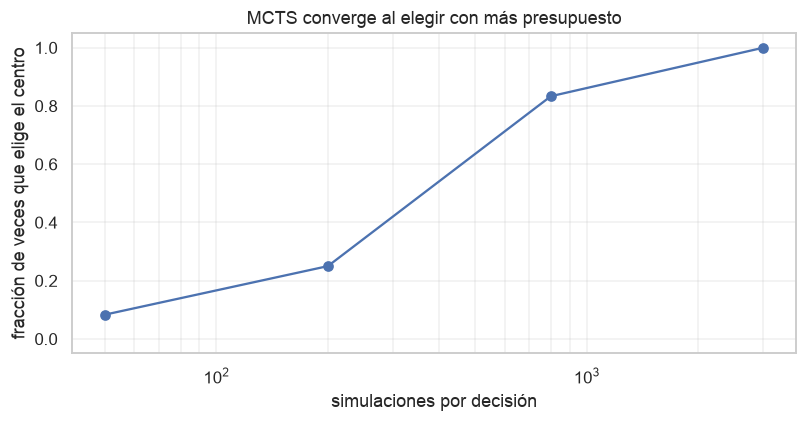

  Esta curva es la propiedad ANYTIME dibujada: más cómputo, mejor jugada, de
  forma continua. Alfa-beta no tiene esta curva — o termina la profundidad d,
  o no te sirve de nada lo que llevaba hecho.


In [16]:
# ¿Cuánto necesita MCTS para converger? Medimos con qué frecuencia encuentra el
# centro, que NO es "la jugada óptima" (todas empatan) sino la que maximiza la
# probabilidad de ganar contra el rival aleatorio que MCTS simula.
jugada_centro = {4}
filas = []
for iters in (50, 200, 800, 3000):
    aciertos, t0 = 0, time.perf_counter()
    for sem in range(12):
        a, _ = mcts(ttt, ttt.inicial, iteraciones=iters, rnd=random.Random(sem))
        aciertos += a in jugada_centro
    filas.append({"simulaciones": iters, "% elige el centro": aciertos / 12,
                  "seg. por decisión": round((time.perf_counter() - t0) / 12, 3)})
conv = pd.DataFrame(filas)
display(conv)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.semilogx(conv["simulaciones"], conv["% elige el centro"], "o-")
ax.set(xlabel="simulaciones por decisión", ylabel="fracción de veces que elige el centro",
       title="MCTS converge al elegir con más presupuesto", ylim=(-.05, 1.05))
ax.grid(alpha=.3, which="both"); plt.tight_layout(); plt.show()
print("""  Esta curva es la propiedad ANYTIME dibujada: más cómputo, mejor jugada, de
  forma continua. Alfa-beta no tiene esta curva — o termina la profundidad d,
  o no te sirve de nada lo que llevaba hecho.""")

In [17]:
# El enfrentamiento directo, que es la única comparación que convence
random.seed(SEED)
estr_mcts = lambda n: (lambda j, s: mcts(j, s, iteraciones=n,
                                         rnd=random.Random(random.randrange(10**6)))[0])

filas = []
g, e, p = torneo(ttt, estr_mcts(300), al_azar, n=20, semilla=1)
filas.append({"enfrentamiento": "MCTS(300) vs azar", "gana": g, "empata": e, "pierde": p})
g, e, p = torneo(ttt, estr_mcts(800), minimax_jug, n=10, semilla=2)
filas.append({"enfrentamiento": "MCTS(800) vs minimax perfecto", "gana": g,
              "empata": e, "pierde": p})
g, e, p = torneo(ttt, minimax_jug, al_azar, n=20, semilla=3)
filas.append({"enfrentamiento": "minimax vs azar", "gana": g, "empata": e, "pierde": p})
display(pd.DataFrame(filas))
print("""
  Cómo leerlo: contra minimax perfecto lo MÁXIMO alcanzable es empatar, porque
  el tres en raya está resuelto en tablas. Que MCTS empate casi siempre
  significa que está jugando prácticamente perfecto — sin conocer una sola
  regla estratégica del juego, solo simulando.

  Y ahí está la lección del capítulo: alfa-beta necesita que TÚ sepas evaluar
  posiciones; MCTS necesita que el juego se pueda SIMULAR rápido. Son dos
  requisitos distintos, y por eso cada uno domina en juegos distintos.""")

,enfrentamiento,gana,empata,pierde
0,MCTS(300) vs azar,19,1,0
1,MCTS(800) vs minimax perfecto,0,10,0
2,minimax vs azar,20,0,0



  Cómo leerlo: contra minimax perfecto lo MÁXIMO alcanzable es empatar, porque
  el tres en raya está resuelto en tablas. Que MCTS empate casi siempre
  significa que está jugando prácticamente perfecto — sin conocer una sola
  regla estratégica del juego, solo simulando.

  Y ahí está la lección del capítulo: alfa-beta necesita que TÚ sepas evaluar
  posiciones; MCTS necesita que el juego se pueda SIMULAR rápido. Son dos
  requisitos distintos, y por eso cada uno domina en juegos distintos.


## 9. Tabla comparativa y árbol de decisión 🧠 *para memorizar antes de la Solemne*

| Algoritmo | Completo | Óptimo | Tiempo | Espacio | Requiere |
|---|---|---|---|---|---|
| **Minimax** | sí | sí (vs. rival óptimo) | $O(b^m)$ | $O(bm)$ | llegar a las hojas |
| **Alfa-beta** | sí | **sí, idéntico a minimax** | $O(b^{m/2})$ mejor caso | $O(bm)$ | buen orden de jugadas |
| **H-minimax (corte)** | sí | **no** | $O(b^d)$ | $O(bd)$ | una buena `Eval` |
| **Expectiminimax** | sí | sí (en esperanza) | $O(b^m n^m)$ | $O(bm)$ | `Eval` en escala correcta |
| **MCTS / UCT** | — | converge al óptimo | *anytime* | $O(\text{iteraciones})$ | simulación rápida |

### Árbol de decisión

```
¿El juego es lo bastante chico para llegar a las hojas?
│
├── SÍ ──► MINIMAX + ALFA-BETA (+ tabla de transposición)
│          resultado exacto; el orden de jugadas es lo que decide el costo
│
└── NO ──► ¿Tienes una función de evaluación decente?
           │
           ├── SÍ ──► ALFA-BETA CON CORTE + Eval
           │          (ajedrez, damas, Conecta 4)
           │          cuidado con el horizon effect
           │
           └── NO ──► ¿Puedes SIMULAR partidas rápido?
                      │
                      ├── SÍ ──► MCTS / UCT   (Go, juegos generales)
                      └── NO ──► no hay método clásico: toca aprender Eval
                                 con datos (AlphaZero, NB-19)

¿Hay AZAR? ──► expectiminimax (y revisa la ESCALA de tu Eval)
¿Hay información OCULTA? (póker) ──► ni minimax ni MCTS puro:
                                      hace falta teoría de juegos
                                      (equilibrio, estrategias mixtas)
```

---

## 10. 📋 Cheat Sheet

### Las fórmulas

```
minimax(s)        = utility(s)                        si terminal
                  = max_a minimax(result(s,a))        si MAX
                  = min_a minimax(result(s,a))        si MIN

alfa-beta         podar cuando  α ≥ β
  α = lo mejor ASEGURADO para MAX hasta ahora (sube)
  β = lo mejor ASEGURADO para MIN hasta ahora (baja)

h-minimax(s,d)    = Eval(s)                           si d = 0

expectiminimax    = Σ_r P(r)·expectiminimax(...)      en nodos de AZAR

UCB1(n)           = W_n/N_n + C·√(ln N_padre / N_n)   con C = √2 para [0,1]
```

### Complejidades

| | mejor caso | caso medio | peor caso |
|---|---|---|---|
| alfa-beta | $O(b^{m/2})$ | $O(b^{3m/4})$ | $O(b^m)$ |

### Los errores que cuestan puntos

- ⚠ Evaluar `utility` desde el jugador **en turno** en vez del de la **raíz**.
- ⚠ Creer que alfa-beta **aproxima**. Da el mismo valor exacto.
- ⚠ En MCTS, elegir la jugada por **tasa de victorias** en vez de por **visitas**.
- ⚠ En la tabla de transposición con poda, guardar el valor **sin el tipo de cota**.
- ⚠ Con azar, suponer que la escala de `Eval` da igual. Da igual **sin** azar.
- ⚠ Olvidar que el corte a profundidad fija produce el ***horizon effect***.

### Los números del tres en raya (útiles para verificar tu código)

| | valor |
|---|---|
| Nodos de minimax completo desde el vacío | ~5,5 × 10⁵ |
| Estados **únicos** alcanzables | ~5.478 |
| Valor minimax de la posición inicial | **0** (empate) |
| Valor minimax de **todas** las aperturas | **0** (ninguna es mejor) |
| Mejor apertura contra juego **imperfecto** | el **centro** |

---

## 11. Conexiones con el mundo real

**IA (CIT-2013).** Materia directa de la Solemne 2. El formato típico pregunta: dado un
árbol con valores en las hojas, (a) calcula el valor minimax, (b) marca qué nodos poda
alfa-beta recorriendo de izquierda a derecha, (c) di cuántas hojas se evaluaron. Hazlo a
mano varias veces: el código no te salva en la prueba.

**Deportes electrónicos y motores de juego.** Stockfish (ajedrez) es alfa-beta muy
afinado con Eval aprendida; AlphaZero combina MCTS con una red neuronal que reemplaza
tanto la `Eval` como la política de simulación.

**Economía y asignación de recursos.** El valor minimax es el análogo del *maximin* en
teoría de juegos. En redes, la asignación de potencia entre usuarios que compiten por el
espectro se modela como juego y se busca el equilibrio.

**Big Data (CIT-2309).** MCTS es un algoritmo *anytime*, igual que LSH (NB-03) y SA
(NB-04): más presupuesto, mejor respuesta, con la posibilidad de parar en cualquier
momento. Si tu sistema tiene que responder dentro de un plazo, los algoritmos *anytime*
son la familia que importa.

**Limitaciones y honestidad.**

- Minimax supone **información perfecta**. En póker o mus no aplica: con información
  oculta hace falta teoría de juegos y estrategias mixtas.
- Supone **un rival óptimo**. Contra un rival predecible y malo, un modelo del rival
  (*opponent modelling*) gana más que jugar minimax.
- MCTS con simulaciones puramente aleatorias es débil en juegos donde una partida al
  azar no se parece en nada a una partida real. Por eso AlphaZero sustituyó el azar por
  una red.

---

## 12. Ejercicios progresivos

### Nivel 1 — Reproducir (guiado): contar hojas evaluadas

Implementa `cuenta_hojas(juego, estado)` que cuente cuántos **nodos terminales** evalúa
minimax y cuántos evalúa alfa-beta sobre el mismo estado. Compáralos para 5 estados
con 2, 3 y 4 jugadas hechas. ¿Crece o decrece la ventaja de alfa-beta al avanzar la
partida? Explica por qué.

In [18]:
# Tu turno (Nivel 1)

#### ✅ Solución — Nivel 1

In [19]:
def cuenta_hojas_minimax(juego, estado, jugador):
    if juego.is_terminal(estado): return 1
    f = max if juego.to_move(estado) == jugador else min
    return sum(cuenta_hojas_minimax(juego, juego.result(estado, a), jugador)
               for a in juego.actions(estado))

def cuenta_hojas_ab(juego, estado, jugador, alfa=-math.inf, beta=math.inf):
    if juego.is_terminal(estado): return 1, juego.utility(estado, jugador)
    hojas = 0
    if juego.to_move(estado) == jugador:
        v = -math.inf
        for a in juego.actions(estado):
            h, vh = cuenta_hojas_ab(juego, juego.result(estado, a), jugador, alfa, beta)
            hojas += h; v = max(v, vh)
            if v >= beta: return hojas, v
            alfa = max(alfa, v)
        return hojas, v
    v = math.inf
    for a in juego.actions(estado):
        h, vh = cuenta_hojas_ab(juego, juego.result(estado, a), jugador, alfa, beta)
        hojas += h; v = min(v, vh)
        if v <= alfa: return hojas, v
        beta = min(beta, v)
    return hojas, v

rnd3 = random.Random(11)
filas = []
for n_jugadas in (2, 3, 4):
    mm, ab = [], []
    for _ in range(5):
        s = estado_al_azar(ttt, n_jugadas, rnd3)
        if ttt.is_terminal(s): continue
        p = ttt.to_move(s)
        mm.append(cuenta_hojas_minimax(ttt, s, p))
        ab.append(cuenta_hojas_ab(ttt, s, p)[0])
    filas.append({"jugadas hechas": n_jugadas, "hojas minimax": int(np.mean(mm)),
                  "hojas alfa-beta": int(np.mean(ab)),
                  "ahorro": f"{1 - np.mean(ab) / np.mean(mm):.1%}"})
display(pd.DataFrame(filas))
print("""
  El ahorro DECRECE al avanzar la partida, y la razón es estructural: la poda
  necesita árbol por debajo para ahorrar. Cerca del final el árbol es poco
  profundo (m pequeño), y como la ventaja es b^m vs b^(m/2), con m chico los
  dos números se parecen. Alfa-beta brilla al principio de la partida, que es
  justo cuando más falta hace.""")

,jugadas hechas,hojas minimax,hojas alfa-beta,ahorro
0,2,3696,459,87.6%
1,3,442,110,75.1%
2,4,82,30,63.0%



  El ahorro DECRECE al avanzar la partida, y la razón es estructural: la poda
  necesita árbol por debajo para ahorrar. Cerca del final el árbol es poco
  profundo (m pequeño), y como la ventaja es b^m vs b^(m/2), con m chico los
  dos números se parecen. Alfa-beta brilla al principio de la partida, que es
  justo cuando más falta hace.


### Nivel 2 — Aplicar (problema nuevo): mejorar la `Eval` de Conecta 4

La `eval_conecta4` de §6.2 ignora algo importante: **una amenaza de 3 en línea solo vale
si la casilla que falta es alcanzable** (hay una ficha debajo o es la fila inferior). Una
amenaza "en el aire" no sirve de nada.

Escribe `eval_conecta4_v2` que distinga amenazas **inmediatas** de amenazas en el aire,
y enfréntala a la versión original a la misma profundidad. ¿Gana? Si no gana, ¿qué
significa eso?

In [20]:
# Tu turno (Nivel 2)

#### ✅ Solución — Nivel 2

In [21]:
def eval_conecta4_v2(juego, estado, jugador):
    t = estado[0]
    rival = "A" if jugador == "R" else "R"

    def alcanzable(i):
        """¿Se puede jugar YA en la casilla i? Solo si está vacía y debajo hay
        suelo o una ficha. Esta es la información que la v1 ignoraba."""
        f, c = divmod(i, juego.COLS)
        if t[i] is not None: return False
        return f == juego.FILAS - 1 or t[juego.idx(f + 1, c)] is not None

    puntaje = 0
    for linea in juego.LINEAS4:
        vals = [t[i] for i in linea]
        mias, suyas = vals.count(jugador), vals.count(rival)
        if mias and suyas: continue                      # cuaterna muerta
        vacias = [i for i in linea if t[i] is None]
        duenio, n = (jugador, mias) if mias else (rival, suyas)
        if n == 0: continue
        if n == 3:
            # la distinción clave: inmediata vale muchísimo más que en el aire
            peso = 120 if any(alcanzable(i) for i in vacias) else 15
        elif n == 2:
            peso = 15 if sum(alcanzable(i) for i in vacias) >= 1 else 6
        else:
            peso = 1
        puntaje += peso if duenio == jugador else -peso
    return puntaje

random.seed(SEED)
res = []
for prof in (3, 4):
    g, e, p = torneo(c4, jugador_alfabeta(prof, eval_conecta4_v2),
                     jugador_alfabeta(prof, eval_conecta4), n=12)
    res.append({"profundidad": prof, "gana v2": g, "empates": e, "gana v1": p})
display(pd.DataFrame(res))
print("""
  Cómo interpretar CUALQUIERA de los dos resultados posibles:

  · Si v2 gana: el conocimiento del dominio que agregaste (alcanzabilidad)
    vale más que el cómputo extra. Es la lección del capítulo: una Eval mejor
    rinde más que un nivel más de profundidad, y es gratis en tiempo.
  · Si empatan o v2 pierde: tampoco es un fracaso. Significa que a ESA
    profundidad la búsqueda ya "ve" las amenazas inalcanzables por sí sola y
    tu refinamiento es redundante. Un refinamiento de Eval que no mejora nada
    es un resultado legítimo que hay que reportar, no esconder.

  La trampa metodológica a evitar: 12 partidas es MUY poco para distinguir dos
  jugadores parecidos. Si la diferencia es de 1-2 partidas, está dentro del
  ruido. Súbelo a 100 antes de afirmar nada.""")

,profundidad,gana v2,empates,gana v1
0,3,6,0,6
1,4,6,0,6



  Cómo interpretar CUALQUIERA de los dos resultados posibles:

  · Si v2 gana: el conocimiento del dominio que agregaste (alcanzabilidad)
    vale más que el cómputo extra. Es la lección del capítulo: una Eval mejor
    rinde más que un nivel más de profundidad, y es gratis en tiempo.
  · Si empatan o v2 pierde: tampoco es un fracaso. Significa que a ESA
    profundidad la búsqueda ya "ve" las amenazas inalcanzables por sí sola y
    tu refinamiento es redundante. Un refinamiento de Eval que no mejora nada
    es un resultado legítimo que hay que reportar, no esconder.

  La trampa metodológica a evitar: 12 partidas es MUY poco para distinguir dos
  jugadores parecidos. Si la diferencia es de 1-2 partidas, está dentro del
  ruido. Súbelo a 100 antes de afirmar nada.


### Nivel 3 — Integrar (NB-04 + NB-06): ¿alfa-beta o MCTS, y cuándo cambia la respuesta?

Hasta aquí comparamos los algoritmos en juegos distintos. Ahora la pregunta de
ingeniería: **en el mismo juego, con el mismo presupuesto de tiempo**, ¿cuál es mejor?

**Tu tarea:**

1. Fija un presupuesto de tiempo por jugada (p. ej. 50 ms).
2. Calibra cuánta profundidad alcanza alfa-beta y cuántas simulaciones alcanza MCTS
   dentro de ese presupuesto, en Conecta 4.
3. Enfréntalos y reporta el resultado **con su incertidumbre**, no como un número
   suelto.
4. Repite con un presupuesto 10× mayor. ¿Cambia el ganador? ¿Por qué?

In [22]:
# Tu turno (Nivel 3)

#### ✅ Solución — Nivel 3

In [23]:
def calibrar(juego, estado, presupuesto_s):
    """Cuánta profundidad y cuántas simulaciones caben en el presupuesto."""
    prof = 1
    while prof < 8:
        t0 = time.perf_counter(); jugador_alfabeta(prof + 1)(juego, estado)
        if time.perf_counter() - t0 > presupuesto_s: break
        prof += 1
    sims, paso = 0, 60
    t0 = time.perf_counter()
    while time.perf_counter() - t0 < presupuesto_s:
        mcts(juego, estado, iteraciones=paso, rnd=random.Random(0)); sims += paso
    return prof, max(sims, paso)

filas = []
for presupuesto in (0.05, 0.5):
    prof, sims = calibrar(c4, c4.inicial, presupuesto)
    random.seed(SEED)
    estr_m = lambda j, s: mcts(j, s, iteraciones=sims,
                               rnd=random.Random(random.randrange(10**6)))[0]
    n = 10
    g, e, p = torneo(c4, jugador_alfabeta(prof), estr_m, n=n, semilla=5)
    # incertidumbre: error estándar de una proporción binomial
    tasa = (g + 0.5 * e) / n
    ee = math.sqrt(max(tasa * (1 - tasa), 1e-9) / n)
    filas.append({"presupuesto/jugada": f"{presupuesto*1000:.0f} ms",
                  "prof. alfa-beta": prof, "sims. MCTS": sims,
                  "gana α-β": g, "empates": e, "gana MCTS": p,
                  "puntaje α-β": f"{tasa:.2f} ± {1.96*ee:.2f}"})
display(pd.DataFrame(filas))
print("""
  Lo que hay que saber leer aquí:

  · El "± " es un intervalo de confianza del 95 % sobre 10 partidas, y es ANCHO
    a propósito: con 10 partidas no se puede distinguir un jugador 55 % de uno
    45 %. Reportar "α-β ganó 6 a 4" sin ese intervalo es sobreinterpretar ruido.
    Esto es lo mismo que te dije en NB-04 §15.3 sobre las corridas de SA.

  · En Conecta 4, alfa-beta parte con ventaja porque eval_conecta4 es DECENTE.
    Donde MCTS gana es donde no existe una Eval buena. El criterio no es cuál
    algoritmo es "mejor", es QUÉ TIENES: si tienes conocimiento del dominio,
    alfa-beta lo aprovecha; si solo tienes un simulador rápido, MCTS.

  · Al subir el presupuesto, alfa-beta gana profundidad de forma LOGARÍTMICA
    (cada nivel cuesta b veces más) mientras MCTS gana simulaciones de forma
    LINEAL. Por eso, a presupuestos muy grandes y b grande, MCTS escala mejor.""")

,presupuesto/jugada,prof. alfa-beta,sims. MCTS,gana α-β,empates,gana MCTS,puntaje α-β
0,50 ms,4,60,10,0,0,1.00 ± 0.00
1,500 ms,6,2280,10,0,0,1.00 ± 0.00



  Lo que hay que saber leer aquí:

  · El "± " es un intervalo de confianza del 95 % sobre 10 partidas, y es ANCHO
    a propósito: con 10 partidas no se puede distinguir un jugador 55 % de uno
    45 %. Reportar "α-β ganó 6 a 4" sin ese intervalo es sobreinterpretar ruido.
    Esto es lo mismo que te dije en NB-04 §15.3 sobre las corridas de SA.

  · En Conecta 4, alfa-beta parte con ventaja porque eval_conecta4 es DECENTE.
    Donde MCTS gana es donde no existe una Eval buena. El criterio no es cuál
    algoritmo es "mejor", es QUÉ TIENES: si tienes conocimiento del dominio,
    alfa-beta lo aprovecha; si solo tienes un simulador rápido, MCTS.

  · Al subir el presupuesto, alfa-beta gana profundidad de forma LOGARÍTMICA
    (cada nivel cuesta b veces más) mientras MCTS gana simulaciones de forma
    LINEAL. Por eso, a presupuestos muy grandes y b grande, MCTS escala mejor.


---

## 13. Resumen y siguiente paso

### Resumen en 6 líneas

1. Un juego es búsqueda con **turnos alternados** y un rival que minimiza tu utilidad;
   el resultado no es una secuencia sino una **estrategia**.
2. **Minimax** da juego óptimo contra rival óptimo, pero cuesta $O(b^m)$.
3. **Alfa-beta** da **exactamente el mismo valor** visitando hasta $O(b^{m/2})$ nodos; el
   **orden de las jugadas** es lo que decide cuánto ahorra.
4. En juegos reales se **corta** a profundidad fija y se usa `Eval` — con el precio del
   ***horizon effect***.
5. Con **azar**, se promedia (expectiminimax) y la **escala** de `Eval` pasa a importar.
6. **MCTS/UCT** cambia conocimiento por simulación: es *anytime*, asimétrico, y no
   necesita `Eval`.

### Checklist antes de la Solemne

Marca solo lo que puedas hacer **sin mirar el notebook**:

- [ ] Calcular a mano el valor minimax de un árbol dibujado.
- [ ] Marcar a mano qué nodos poda alfa-beta de izquierda a derecha, y contar hojas.
- [ ] Explicar por qué el mejor orden de jugadas da $O(b^{m/2})$.
- [ ] Decir qué es el *horizon effect* y cómo se mitiga.
- [ ] Escribir UCB1 de memoria y explicar qué hace cada término.
- [ ] Justificar cuándo elegir MCTS en lugar de alfa-beta.

### Siguiente paso

→ **Continúa en: NB-06 — Satisfacción de Restricciones (CSP)** (AIMA cap. 6). Ahí el
estado deja de ser "una posición" y pasa a ser **una asignación parcial de variables**,
y el *backtracking* resulta ser el DFS de NB-04 con propagación encima. Más adelante:
**NB-08** (probabilidad y HMM, que retoma la esperanza de §7) y **NB-19** (aprendizaje
por refuerzo, donde MCTS reaparece como la base de AlphaZero).

### Para profundizar

- *AIMA 4.ª ed.*, cap. 5: 5.2 (minimax), 5.3 (alfa-beta y el análisis de Knuth & Moore),
  5.4 (corte, Eval, *horizon effect*, quiescencia), 5.5 (MCTS y UCT), 5.6 (estocásticos),
  5.7 (información parcial).
- Knuth, D. & Moore, R. (1975). *An analysis of alpha-beta pruning* — de aquí sale el
  $b^{m/2}$.
- Silver et al. (2017). *Mastering the game of Go without human knowledge* — AlphaZero:
  MCTS con la `Eval` y la política aprendidas por una red.